# MERSCOPE Tongue — Local Ligand–Receptor Map Agreement (LIANA+)

**Paper figures**: Fig 4j,k, Fig S15 (Supplementary Note S5)

Cell–cell communication analysis depends on which cells sit next to each other, not only on cell-type labels.
This notebook asks whether RNA transferred onto the protein (PCF) section with SAME reproduces the local
ligand–receptor (LR) patterns measured on the RNA (MERSCOPE) section, compared with a nearest same-celltype
baseline that matches cell types but ignores the coordinated spatial assignment.

**Dataset**: 3,608 MERSCOPE cells (template, 300 genes) and the 3,579 PCF cells matched by SAME (query; dp = 10,
knn = 8, single cells). Cell types: Endothelial, Epithelial, Fibroblasts, Lymphoid, Myeloid.

| Step | Setting |
|------|---------|
| SAME result | `results/dp10_knn8_MS1` (paper run) |
| Baseline | nearest same-celltype in the initial (image-based) registration |
| LIANA+ | v1.7.3, bivariate local Moran's R, consensus resource, 100 permutations |
| Graph | binary Delaunay on native µm coordinates |
| Expression | MERSCOPE counts, `normalize_total` + `log1p` |
| Maps | Gaussian windows 25–100 µm, lattice spacing = window / 2, ≥ 2 summed kernel weight |
| Agreement | Spearman correlation vs RNA-only map, median over LR pairs |


## Workflow

1. **Two RNA reconstructions on the same protein-section cells.** Every SAME-matched protein-section cell receives
   the RNA profile of one RNA-section cell:
   * **SAME**: its SAME partner (the published dp = 10 run);
   * **Nearest same-celltype** (baseline): the closest RNA-section cell of the same cell type in the initial,
     image-based registration, chosen independently for each cell (RNA cells can be reused).

   Both reconstructions use identical protein-section positions and differ only in the transferred RNA.
2. **Local LR scores with LIANA+.** Bivariate local Moran's R (consensus resource, binary Delaunay graph on native
   coordinates) is computed three times: on the RNA section with its measured RNA ("RNA-only"), and on the protein
   section with each transferred profile. Each run gives one score per cell and LR pair.
3. **Smooth into maps.** For each run and LR pair, per-cell scores are averaged with a Gaussian kernel (full width
   at half maximum 25, 50, 75 or 100 µm) on a common lattice in the initial shared registration. Lattice spacing is
   half the kernel width; kernels are truncated at 3σ; only lattice points with a summed kernel weight of at least 2
   in every map are kept.
4. **Compare maps.** Agreement with the RNA-only map is the Spearman correlation across lattice points, per LR pair,
   summarised as the median across LR pairs. No cell partners are used to define the reference scores.

LR pairs: those passing LIANA+'s default 5% expression filter in all three runs; the figures use the pairs with a
spatial pattern in the RNA section (RNA-only global Moran permutation p < 0.05, unadjusted). All expression-eligible
pairs are reported as a sensitivity analysis.


### Requirements

Run from `examples/tongue/` after downloading the SAME data archive from Zenodo
(<https://zenodo.org/records/19056915>, see `examples/README.md`). Besides SAME's own requirements
(`pip install -r requirements.txt` at the repo root; needed to unpickle the MetaCell objects), this notebook uses
LIANA+ and scanpy. Versions used to produce the paper figures:

```bash
pip install -r requirements.txt "liana==1.7.3" "scanpy==1.11.4" "anndata==0.10.9" \
    "numpy==1.26.4" "scipy==1.16.2" "pandas==2.3.2" "matplotlib==3.10.6"
```

Runtime: under a minute on a laptop (three LIANA+ runs with 100 permutations each).


## Setup

In [1]:
import pickle
import sys
import warnings
from pathlib import Path

import anndata as ad
import liana as li
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy
from matplotlib.patches import Rectangle
from scipy.sparse import csr_matrix
from scipy.spatial import Delaunay, cKDTree
from scipy.stats import rankdata

warnings.filterwarnings('ignore', category=FutureWarning)

NOTEBOOK_DIR = Path('.').resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parents[1]
sys.path.insert(0, str(PROJECT_ROOT))  # SAME's `src` package (MetaCell class, needed to unpickle results)

DATA_DIR = NOTEBOOK_DIR / 'data'
RESULTS_DIR = NOTEBOOK_DIR / 'results'
FIG_DIR = NOTEBOOK_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
                     'svg.fonttype': 'none', 'pdf.fonttype': 42, 'font.size': 8})

print(f'liana {li.__version__} | scanpy {sc.__version__} | anndata {ad.__version__} | '
      f'numpy {np.__version__} | scipy {scipy.__version__} | pandas {pd.__version__}')

liana 1.7.3 | scanpy 1.11.4 | anndata 0.10.9 | numpy 1.26.4 | scipy 1.16.2 | pandas 2.3.2


In [2]:
# analysis parameters (Supplementary Note S5)
WINDOWS_UM = (25, 50, 75, 100)  # Gaussian kernel full width at half maximum, µm
MIN_WEIGHT = 2.0                # minimum summed kernel weight per lattice point, in every map
ALPHA = 0.05                    # RNA-only global Moran permutation p-value for 'spatially patterned' LR pairs
N_PERMS, SEED = 100, 1337       # LIANA+ permutations and seed

SAME_COLOR, NN_COLOR = '#2B7FFF', '#FF2056'
INK, INK2, GRID = '#1f1f1f', '#5f6368', '#e6e6e3'
METHODS = ('SAME', 'Nearest same-celltype')

## Helper functions

The whole analysis is a few small functions: a Delaunay graph, a LIANA+ call, the nearest same-celltype baseline,
Gaussian map smoothing and a column-wise Spearman correlation.

In [3]:
def delaunay_graph(xy):
    """Binary, symmetric adjacency matrix of the Delaunay triangulation of points `xy` (n x 2)."""
    s = Delaunay(np.asarray(xy, float)).simplices
    i = np.concatenate([s[:, 0], s[:, 1], s[:, 0], s[:, 1], s[:, 2], s[:, 2]])
    j = np.concatenate([s[:, 1], s[:, 2], s[:, 2], s[:, 0], s[:, 1], s[:, 0]])
    adj = csr_matrix((np.ones(len(i)), (i, j)), shape=(len(xy), len(xy)))
    adj.data[:] = 1.0
    return adj


def liana_local(X, xy, genes, normalize):
    """LIANA+ bivariate local Moran's R for every consensus LR pair; returns an AnnData (units x LR pairs)
    with local scores in .X and global Moran's R / permutation p-values in .var."""
    adata = ad.AnnData(X=np.asarray(X, dtype=float), var=pd.DataFrame(index=list(genes)))
    if normalize:
        sc.pp.normalize_total(adata)
        sc.pp.log1p(adata)
    adata.obsp['spatial_connectivities'] = delaunay_graph(xy)
    return li.mt.bivariate(adata, local_name='morans', global_name='morans', use_raw=False,
                           resource_name='consensus', connectivity_key='spatial_connectivities',
                           n_perms=N_PERMS, seed=SEED, mask_negatives=False, verbose=False)


def nearest_same_celltype(query_xy, query_type, ref_xy, ref_type):
    """For each query unit, the index of the closest reference unit of the same cell type (reuse allowed)."""
    partner = np.full(len(query_xy), -1)
    for t in np.unique(query_type):
        q, r = np.where(query_type == t)[0], np.where(ref_type == t)[0]
        partner[q] = r[cKDTree(ref_xy[r]).query(query_xy[q], k=1)[1]]
    return partner


def units_per_um(native_xy, frame_xy):
    """Scale of the registration frame relative to native µm coordinates."""
    a, b = native_xy - native_xy.mean(0), frame_xy - frame_xy.mean(0)
    return float(np.sqrt((b ** 2).sum() / (a ** 2).sum()))


def make_lattice(lo, hi, window_um, scale):
    """Square lattice with spacing = half the window width, in registration-frame units."""
    step = window_um / 2 * scale
    xs, ys = np.arange(lo[0], hi[0], step), np.arange(lo[1], hi[1], step)
    gx, gy = np.meshgrid(xs, ys)
    return np.c_[gx.ravel(), gy.ravel()], gx.shape


def smooth(values, xy, lattice, sigma):
    """Gaussian-weighted mean of per-unit `values` (n x k) at each lattice point (truncated at 3 sigma);
    also returns the summed kernel weight per lattice point."""
    D = cKDTree(lattice).sparse_distance_matrix(cKDTree(xy), 3 * sigma, output_type='coo_matrix').tocsr()
    D.data = np.exp(-D.data ** 2 / (2 * sigma ** 2))
    weight = np.asarray(D.sum(1)).ravel()
    return (D @ values) / np.maximum(weight, 1e-12)[:, None], weight


def spearman_cols(A, B):
    """Spearman correlation between matching columns of A and B (ties averaged)."""
    A, B = rankdata(A, axis=0), rankdata(B, axis=0)
    A, B = A - A.mean(0), B - B.mean(0)
    return (A * B).sum(0) / np.sqrt((A * A).sum(0) * (B * B).sum(0))


def map_agreement(scores, rna_xy, prot_xy, scale, pairs):
    """Median Spearman agreement with the RNA-only map at each window width, plus per-pair correlations."""
    lo, hi = np.minimum(rna_xy.min(0), prot_xy.min(0)), np.maximum(rna_xy.max(0), prot_xy.max(0))
    rows, per_pair = [], {}
    for w in WINDOWS_UM:
        lattice, _ = make_lattice(lo, hi, w, scale)
        sigma = w / 2.355 * scale
        g, wg = smooth(scores['RNA-only'][:, pairs], rna_xy, lattice, sigma)
        s, ws = smooth(scores['SAME'][:, pairs], prot_xy, lattice, sigma)
        n, wn = smooth(scores['Nearest same-celltype'][:, pairs], prot_xy, lattice, sigma)
        ok = (wg >= MIN_WEIGHT) & (ws >= MIN_WEIGHT) & (wn >= MIN_WEIGHT)
        r_same, r_nn = spearman_cols(s[ok], g[ok]), spearman_cols(n[ok], g[ok])
        per_pair[w] = pd.DataFrame({'SAME': r_same, 'Nearest same-celltype': r_nn}, index=pairs)
        rows.append({'window_um': w, 'lattice_points': int(ok.sum()), 'LR_pairs': len(pairs),
                     'SAME': np.median(r_same), 'Nearest same-celltype': np.median(r_nn),
                     'difference': np.median(r_same) - np.median(r_nn),
                     'SAME_higher': f'{int((r_same > r_nn).sum())}/{len(pairs)}'})
    return pd.DataFrame(rows).set_index('window_um'), per_pair


def dense(adata):
    return adata.X.toarray() if hasattr(adata.X, 'toarray') else np.asarray(adata.X)

In [4]:
def plot_by_scale(table, title, fname):
    """Median agreement with the RNA-only LR maps at each window width."""
    fig, ax = plt.subplots(figsize=(3.6, 2.4))
    for col, color in zip(METHODS, (SAME_COLOR, NN_COLOR)):
        ax.plot(table.index, table[col], color=color, lw=1.4, label=col)
        ax.plot(table.index, table[col], 'o', ms=4.5, mfc=color, mec='white', mew=1.0)
    ax.set_xticks(WINDOWS_UM); ax.set_xlim(20, 105); ax.set_ylim(min(0.4, np.floor(table[list(METHODS)].min().min() * 10) / 10), 1.0)
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_xlabel('Map resolution (window width, µm)')
    ax.set_ylabel('Cell-cell communication agreement\n(median Spearman correlation)')
    ax.set_title(title, loc='left', fontsize=8)
    ax.legend(frameon=False, loc='upper left')
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    for ext in ('svg', 'png'):
        fig.savefig(FIG_DIR / f'{fname}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()


def plot_per_pair(per_pair, title, fname):
    """Agreement for each LR pair at one window width (dumbbell plot)."""
    p = per_pair.sort_values('SAME')
    y = np.arange(len(p))
    headroom = 1.6 if len(p) <= 8 else 0.0   # room for the legend above short lists
    fig, ax = plt.subplots(figsize=(3.8, 0.9 + 0.17 * (len(p) + headroom)))
    ax.hlines(y, p.min(1), p.max(1), color='#c9c9c6', lw=1.0, zorder=1)
    ax.plot(p['Nearest same-celltype'], y, 'o', ms=4.5, mfc=NN_COLOR, mec='white', mew=0.9, zorder=2, label='Nearest same-celltype')
    ax.plot(p['SAME'], y, 'o', ms=4.5, mfc=SAME_COLOR, mec='white', mew=0.9, zorder=3, label='SAME')
    ax.set_yticks(y); ax.set_yticklabels([s.replace('^', '–').replace('_', '/') for s in p.index], fontsize=7)
    ax.set_xlim(0, 1); ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0]); ax.set_ylim(-0.7, len(p) - 0.3 + headroom)
    ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_xlabel('Agreement at 50 µm (Spearman correlation)')
    ax.set_title(title, loc='left', fontsize=8)
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], frameon=False, loc='upper left', handletextpad=0.2)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    for ext in ('svg', 'png'):
        fig.savefig(FIG_DIR / f'{fname}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()

## 1. Load cells, expression and coordinates

* `prot_df.csv` / `mer_df.csv`: cell types and coordinates in the initial (image-based) registration
  (`transformed_x`, `transformed_y`);
* `pcfSubAD.h5ad` / `merSubAD.h5ad`: native µm coordinates; MERSCOPE raw counts (300 genes).

In [5]:
CELL_TYPES = ['Endothelial cells', 'Epithelial cells', 'Fibroblasts', 'Lymphoid cells', 'Myeloid cells']

prot_df = pd.read_csv(DATA_DIR / 'prot_df.csv', index_col=0)
mer_df = pd.read_csv(DATA_DIR / 'mer_df.csv', index_col=0)
pcf = ad.read_h5ad(DATA_DIR / 'pcfSubAD.h5ad')
mer = ad.read_h5ad(DATA_DIR / 'merSubAD.h5ad')

# PCF (protein) cells, indexed by cell id
prot_df.index = prot_df['Cell_Num'].astype(str)
assert (pcf.obs['Object ID'].astype(str).values == prot_df.index.values).all()
prot_type = prot_df[CELL_TYPES].idxmax(axis=1)
prot_frame = prot_df[['transformed_x', 'transformed_y']].astype(float)
prot_native = pd.DataFrame(pcf.obs[['Centroid X µm', 'Centroid Y µm']].to_numpy(float), index=prot_df.index)

# MERSCOPE (RNA) cells, in merSubAD order
assert (mer.obs_names.astype(str) == mer_df['Cell_Num'].astype(str).values).all()
rna_ids = mer.obs_names.astype(str)
rna_type = mer_df[CELL_TYPES].idxmax(axis=1).to_numpy()
rna_frame = mer_df[['transformed_x', 'transformed_y']].to_numpy(float)
rna_native = mer.obs[['center_x', 'center_y']].to_numpy(float)
rna_counts = mer.X.toarray() if hasattr(mer.X, 'toarray') else np.asarray(mer.X)
genes = list(mer.var_names)

print(f'PCF cells: {len(prot_df)} | MERSCOPE cells: {len(rna_ids)} | genes: {len(genes)}')

PCF cells: 4671 | MERSCOPE cells: 3608 | genes: 300


## 2. SAME partners and the nearest same-celltype baseline

`matchedDF.csv` lists each SAME match by metacell id (`Aligned_metacell_id` → `Ref_metacell_id`); with
metacell size 1 each metacell is one cell. (The `aligned_idx` / `ref_idx` columns are indices within each sliding
window, so the metacell id columns are used here.) The match coordinates are checked against the metacell tables.

In [6]:
run_dir = RESULTS_DIR / 'dp10_knn8_MS1'
mc_align = pickle.load(open(run_dir / 'mc_align.pkl', 'rb'))
mc_ref = pickle.load(open(run_dir / 'mc_ref.pkl', 'rb'))
matches = pd.read_csv(run_dir / 'matchedDF.csv')

A = mc_align.metacell_df.set_index('metacell_id')
R = mc_ref.metacell_df.set_index('metacell_id')
assert np.allclose(A.loc[matches['Aligned_metacell_id'], ['X', 'Y']].to_numpy(float), matches[['X', 'Y']].to_numpy(float))
assert np.allclose(R.loc[matches['Ref_metacell_id'], ['X', 'Y']].to_numpy(float), matches[['ref_X', 'ref_Y']].to_numpy(float))
same_pairs = dict(zip(A.loc[matches['Aligned_metacell_id'], 'members'].map(lambda m: str(m[0])),
                      R.loc[matches['Ref_metacell_id'], 'members'].map(lambda m: str(m[0]))))

# protein cells analysed: every SAME-matched PCF cell (in prot_df order)
cells = [c for c in prot_df.index if c in same_pairs]
rna_pos = pd.Series(np.arange(len(rna_ids)), index=rna_ids)
partner = {'SAME': rna_pos.loc[[same_pairs[c] for c in cells]].to_numpy(),
           'Nearest same-celltype': nearest_same_celltype(prot_frame.loc[cells].to_numpy(), prot_type.loc[cells].to_numpy(),
                                                          rna_frame, rna_type)}
p_type = prot_type.loc[cells].to_numpy()
for m, j in partner.items():
    print(f'{m:22s}: {len(cells)} PCF cells | same cell type as partner {np.mean(rna_type[j] == p_type):.1%} | '
          f'distinct RNA partners {len(np.unique(j))}')

SAME                  : 3579 PCF cells | same cell type as partner 84.2% | distinct RNA partners 3579
Nearest same-celltype : 3579 PCF cells | same cell type as partner 100.0% | distinct RNA partners 2210


## 3. LIANA+ local LR scores

Three runs on the same 300 genes: the MERSCOPE section with its own RNA, and the PCF section with RNA from SAME or
from the baseline. The two reconstructions share the PCF positions and Delaunay graph.

In [7]:
p_native = prot_native.loc[cells].to_numpy()
runs = {'RNA-only': liana_local(rna_counts, rna_native, genes, normalize=True),
        'SAME': liana_local(rna_counts[partner['SAME']], p_native, genes, normalize=True),
        'Nearest same-celltype': liana_local(rna_counts[partner['Nearest same-celltype']], p_native, genes, normalize=True)}

# LR pairs passing LIANA+'s 5% expression filter in all three runs
pairs_all = runs['RNA-only'].var_names.intersection(runs['SAME'].var_names).intersection(runs['Nearest same-celltype'].var_names)
scores = {k: dense(v[:, pairs_all]) for k, v in runs.items()}
rna_stats = runs['RNA-only'].var.loc[pairs_all, ['ligand', 'receptor', 'morans', 'morans_pvals']]
pairs_sig = list(rna_stats.index[rna_stats['morans_pvals'] < ALPHA])
print(f'{len(pairs_all)} expression-eligible LR pairs; {len(pairs_sig)} with an RNA-only spatial pattern (p < {ALPHA})')
rna_stats.assign(used=rna_stats.index.isin(pairs_sig)).round(3)

18 expression-eligible LR pairs; 15 with an RNA-only spatial pattern (p < 0.05)


,ligand,receptor,morans,morans_pvals,used
interaction,,,,,
TGFA^EGFR_ERBB2,TGFA,EGFR_ERBB2,0.030,0.00,True
TGFA^ERBB3,TGFA,ERBB3,0.004,0.55,False
ICAM1^EGFR,ICAM1,EGFR,-0.058,0.00,True
ICAM1^IL2RG,ICAM1,IL2RG,0.018,0.01,True
CDH1^EGFR,CDH1,EGFR,0.093,0.00,True
EPGN^EGFR,EPGN,EGFR,-0.026,0.00,True
COL1A1^SDC1,COL1A1,SDC1,-0.429,0.00,True
FN1^SDC1,FN1,SDC1,-0.135,0.00,True
IGF2^INSR,IGF2,INSR,0.036,0.00,True


## 4. Map agreement across window widths

Lattice and kernel widths are in µm; the registration frame is scaled relative to µm, so the scale is estimated
from the PCF cells' native and registered coordinates.

In [8]:
scale = units_per_um(p_native, prot_frame.loc[cells].to_numpy())
col = {p: i for i, p in enumerate(pairs_all)}
idx_sig, idx_all = [col[p] for p in pairs_sig], [col[p] for p in pairs_all]
p_frame = prot_frame.loc[cells].to_numpy()

table, per_pair = map_agreement(scores, rna_frame, p_frame, scale, idx_sig)
for w in per_pair: per_pair[w].index = pairs_sig
print(f'registration units per µm: {scale:.3f}')
table.round(3)

registration units per µm: 1.972


,lattice_points,LR_pairs,SAME,Nearest same-celltype,difference,SAME_higher
window_um,,,,,,
25,1445,15,0.704,0.586,0.119,14/15
50,2461,15,0.779,0.696,0.083,15/15
75,1469,15,0.849,0.733,0.117,15/15
100,892,15,0.877,0.760,0.117,15/15


**Sensitivity**: all expression-eligible LR pairs, without the spatial-pattern filter.

In [9]:
table_all, _ = map_agreement(scores, rna_frame, p_frame, scale, idx_all)
table_all.round(3)

,lattice_points,LR_pairs,SAME,Nearest same-celltype,difference,SAME_higher
window_um,,,,,,
25,1445,18,0.673,0.581,0.093,16/18
50,2461,18,0.773,0.686,0.088,18/18
75,1469,18,0.837,0.731,0.106,18/18
100,892,18,0.873,0.756,0.117,18/18


## 5. Figures

### Fig S15a — agreement by window width

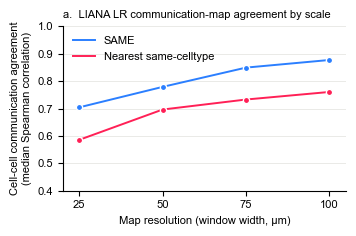

In [10]:
plot_by_scale(table, 'a.  LIANA LR communication-map agreement by scale', 'FigS15a_liana_agreement_by_scale')

### Fig 4k — agreement per LR pair at 50 µm

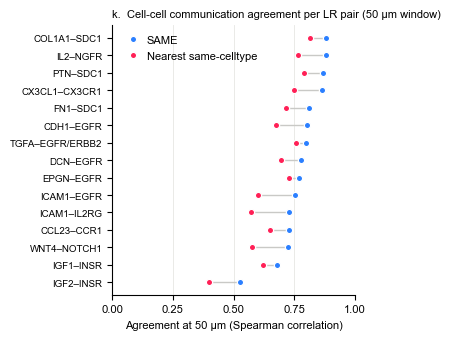

In [11]:
plot_per_pair(per_pair[50], 'k.  Cell-cell communication agreement per LR pair (50 µm window)', 'Fig4k_liana_agreement_per_pair')

### Fig S15b — DCN–EGFR maps at 50 µm

LIANA+ local scores for DCN–EGFR smoothed at 50 µm, for the MERSCOPE section and the PCF section reconstructed
with SAME or the baseline. Purple and orange are negative and positive local Moran's R: for this pair, purple marks
DCN and EGFR expressed on opposite sides of the stroma–epithelium boundary, orange marks concordant expression
(including concordantly low expression). Correlations use all eligible lattice points of the whole-tissue maps.
The 300 µm box is the representative region shown in the paper.

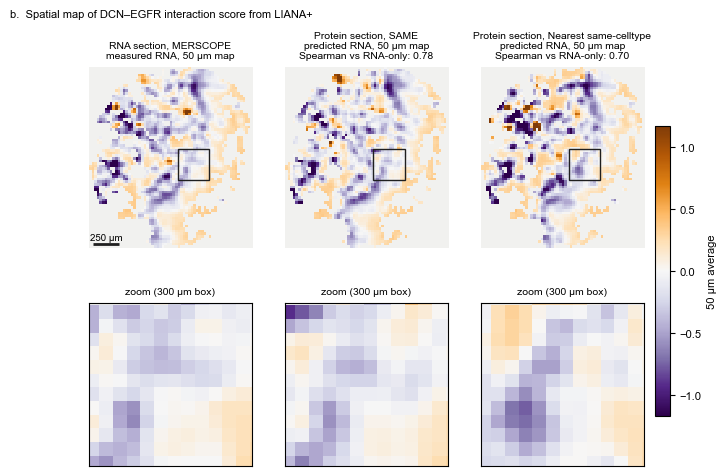

{'SAME': 0.779, 'Nearest same-celltype': 0.696}


In [12]:
def plot_lr_maps(pair, window_um=50, box_um=300, box_corner_um=(843.75, 781.25), fname=None):
    k = col[pair]
    xy = {'RNA-only': rna_frame, 'SAME': p_frame, 'Nearest same-celltype': p_frame}
    lo = np.minimum(rna_frame.min(0), p_frame.min(0)); hi = np.maximum(rna_frame.max(0), p_frame.max(0))
    lattice, shape = make_lattice(lo, hi, window_um, scale)
    sigma, px = window_um / 2.355 * scale, window_um / 2
    maps, ok = {}, np.ones(len(lattice), bool)
    for m in xy:
        v, w = smooth(scores[m][:, [k]], xy[m], lattice, sigma)
        maps[m] = v[:, 0]; ok &= w >= MIN_WEIGHT
    rho = {m: spearman_cols(maps[m][ok, None], maps['RNA-only'][ok, None])[0] for m in METHODS}
    extent = [-px / 2, (shape[1] - 0.5) * px, (shape[0] - 0.5) * px, -px / 2]   # µm from the lattice origin
    vmax = np.percentile(np.abs(np.concatenate([maps[m][ok] for m in maps])), 98)
    cmap = plt.get_cmap('PuOr_r').copy(); cmap.set_bad('#f1f1ef')
    titles = {'RNA-only': 'RNA section, MERSCOPE\nmeasured RNA, 50 µm map',
              'SAME': f'Protein section, SAME\npredicted RNA, 50 µm map\nSpearman vs RNA-only: {rho["SAME"]:.2f}',
              'Nearest same-celltype': 'Protein section, Nearest same-celltype\npredicted RNA, 50 µm map\n'
                                       f'Spearman vs RNA-only: {rho["Nearest same-celltype"]:.2f}'}
    fig, ax = plt.subplots(2, 3, figsize=(7.5, 5.4))
    bx, by = box_corner_um
    for j, m in enumerate(maps):
        img = np.where(ok, maps[m], np.nan).reshape(shape)
        for r in (0, 1):
            im = ax[r, j].imshow(img, cmap=cmap, vmin=-vmax, vmax=vmax, extent=extent, interpolation='nearest')
            ax[r, j].set_xticks([]); ax[r, j].set_yticks([]); ax[r, j].set_aspect('equal')
        ax[0, j].set_xlim(extent[0], extent[1]); ax[0, j].set_ylim(extent[2], extent[3])
        ax[0, j].add_patch(Rectangle((bx, by), box_um, box_um, fill=False, ec=INK, lw=1.0))
        for s in ax[0, j].spines.values(): s.set_visible(False)
        ax[0, j].set_title(titles[m], fontsize=7.5)
        ax[1, j].set_xlim(bx, bx + box_um); ax[1, j].set_ylim(by + box_um, by)
        ax[1, j].set_title(f'zoom ({box_um} µm box)', fontsize=7.5)
    ax[0, 0].plot([30, 280], [extent[2] - 40] * 2, color=INK, lw=2, solid_capstyle='butt')
    ax[0, 0].text(155, extent[2] - 60, '250 µm', ha='center', va='bottom', fontsize=7)
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.set_label(f'{window_um} µm average')
    fig.suptitle(f'b.  Spatial map of {pair.replace("^", "–")} interaction score from LIANA+', x=0.02, ha='left', fontsize=8)
    if fname:
        for ext in ('svg', 'png'):
            fig.savefig(FIG_DIR / f'{fname}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()
    return rho


rho = plot_lr_maps('DCN^EGFR', fname='FigS15b_DCN_EGFR_maps')
print({m: round(float(v), 3) for m, v in rho.items()})

## Summary

At 50 µm the median Spearman correlation with the RNA-only LR maps is about 0.78 for SAME and 0.70 for nearest
same-celltype assignment across the 15 spatially patterned LR pairs, with SAME higher for every pair; SAME is higher
at all four window widths. Including all 18 expression-eligible pairs gives 0.77 vs 0.69. Nearest same-celltype
assignment preserves cell-type labels but, where the two sections differ locally, borrows RNA from more distant or
repeatedly used cells, which displaces local communication patterns.